# 7 · The temperature model, corrected at the wells, and the forecasts re-run

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

Notebook 6 found the FORGE temperature model (GDR 1205), which every forecast starts from, hot at the wells: about +6 °C at the 16B gauge (GDR 1608). A second check on the 16A temperature log of August 2021 (GDR 1421) finds the same. The owner decided (30 October 2026) that the forecasts must correct for it. This notebook:

1. checks the model along 16A against the 2021 log (and recomputes that check here from the derived data);
2. fits a local correction at the wells, with its uncertainty, and checks it against the 16B gauge;
3. shows every forecast the case page quotes **before and after** the correction: the 30-year temperature at 5, 10 and 20 kg/s, the start temperature, heat output (MWth), breakthrough, the August 2024 produced-temperature misfit, the pressure limit under both Shmin cases, and the decision chart's tie to FORGE;
4. reads the 16B minifrac shut-in pressures directly from the GDR 1570 files, as a check on the GDR 1596 report's 0.60 psi/ft.

**New data** (DOE Geothermal Data Repository, CC BY 4.0, licence read on each GDR page on 30 October 2026; SHA-256 in `DATA.md`; only derived values in `data/`):
* **GDR 1421**: deep-well temperature surveys (workbook of September 2022); the 16A(78)-32 log of 16 August 2021, about 216 days after the rig left. `data/temp_16A_gdr1421_5m.csv` holds its median every 5 m.
* **GDR 1570**: Baker Hughes minifrac LAS files from 16B(78)-32 (June–July 2023). Only the shut-in pressures derived by the engine are quoted.

*Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**Labels.** Every model number is **simulated** by the KAI Reservoir Lab engine (`results/kai_engine_phase6.json`, `kai-engine reference forge-phase6`). The same 20 phase 4 members are re-run; only the starting temperatures change (and each member's aperture factor is refitted to the August pressures, because colder water is a little more viscous).

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase6.json").read_text())      # KAI engine run (simulated)
P4 = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())
P5 = json.loads(pathlib.Path("results/kai_engine_phase5.json").read_text())
C, B4 = E["corrected"], E["corrected"]["before_phase4"]
def pct(d, f="{:.1f}"):
    return f"{f.format(d['P50'])} ({f.format(d['P10'])} to {f.format(d['P90'])})"
print(E["label"]); print("run id:", E["run_id"]); print("sources:", ", ".join(f"GDR {s['gdr']} ({s['licence']})" for s in E["sources"].values()))

simulated (KAI engine TPFA solver); measured values are labelled measured
run id: forge-phase6-2026-10-30-30a594b585
sources: GDR 1608 (CC BY 4.0), GDR 1421 (CC BY 4.0), GDR 1570 (CC BY 4.0)


## 1 · The temperature model against the 16A log

The 2021 log was run 216 days after drilling, so the rock had mostly recovered from the cooling by the drilling mud. The model was built before the 16A and 16B wells existed, so this is a blind check. Below we recompute the model along 16A from `data/forge_model.npz` and the trajectory, compare it with the log, and stop if our numbers differ from the engine's by more than 0.5 °C.

rmse       notebook +7.11 °C   engine +7.11 °C
bias       notebook +6.99 °C   engine +6.98 °C
open_bias  notebook +5.91 °C   engine +5.91 °C


,log_c,model_c,bias_c,tvd
0,87.5,92.5,5.0,600-900 m
1,106.7,114.5,7.7,900-1200 m
2,127.4,135.9,8.5,1200-1500 m
3,147.3,156.0,8.7,1500-1800 m
4,168.9,176.5,7.6,1800-2100 m
5,192.9,199.4,6.5,2100-2400 m
6,213.0,218.9,5.9,2400-2700 m


16B producing depths (2331-2518 m): model 215.3 °C, 16A log at the same depths 207.1 °C → model +8.2 °C
16B gauge (GDR 1608, 2043 m): model 183.6 °C, static 177.9 °C (174.2-194.4); the 16A log at that depth reads 176.0 °C


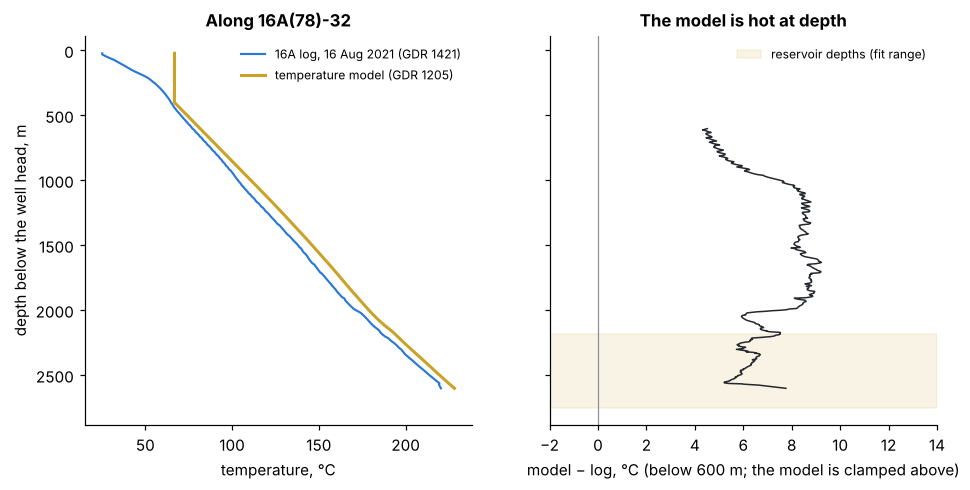

In [2]:
log = pd.read_csv("data/temp_16A_gdr1421_5m.csv")
m = np.load("data/forge_model.npz"); tr = json.loads(str(m["transform"]))
tj = pd.read_csv("data/trajectories_16A_16B.csv")
A = tj[tj.well == "16A(78)-32"]
E_, N_, Z_ = (np.interp(log.md_m, A.md_m, A[c]) for c in ("easting", "northing", "elev_m"))
tvd = A.elev_m.iloc[0] - Z_
T_mod = ft.along_well(m["T_c"].astype(float), tr, E_, N_, Z_)
res = T_mod - log.T_c.values
deep = tvd > 600
mine = {"rmse": float(np.sqrt(np.mean(res[deep] ** 2))), "bias": float(np.mean(res[deep]))}
lo, hi = 9270 * ft.FT, 10938.3 * ft.FT
op = (log.md_m >= lo) & (log.md_m <= hi)
mine["open_bias"] = float(np.mean(res[op]))
G = E["geotherm"]
for k, e in (("rmse", G["log_16A"]["rmse_c"]), ("bias", G["log_16A"]["bias_c"]), ("open_bias", G["log_16A"]["open_interval"]["bias_c"])):
    print(f"{k:10} notebook {mine[k]:+.2f} °C   engine {e:+.2f} °C"); assert abs(mine[k] - e) < 0.5, k
display(pd.DataFrame(G["log_16A"]["bins"]).assign(tvd=lambda d: d.tvd_m.map(lambda v: f"{v[0]}-{v[1]} m")).drop(columns="tvd_m").round(1))
print(f"16B producing depths ({G['producing_zone_16B']['tvd_m'][0]:.0f}-{G['producing_zone_16B']['tvd_m'][1]:.0f} m): model {G['producing_zone_16B']['model_c']:.1f} °C, "
      f"16A log at the same depths {G['producing_zone_16B']['log_16A_same_tvd_c']:.1f} °C → model {G['producing_zone_16B']['model_minus_log_c']:+.1f} °C")
g = G["gauge_16B_gdr1608"]
print(f"16B gauge (GDR 1608, {g['tvd_m']:.0f} m): model {g['model_c']:.1f} °C, static {g['static_recovery_fit_c']:.1f} °C "
      f"({g['static_range_c'][0]:.1f}-{g['static_range_c'][1]:.1f}); the 16A log at that depth reads {g['log_16A_same_tvd_c']:.1f} °C")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
ax[0].plot(log.T_c, tvd, color=BLUE, lw=1.4, label="16A log, 16 Aug 2021 (GDR 1421)")
ax[0].plot(T_mod, tvd, color=GOLD, lw=2, label="temperature model (GDR 1205)")
ax[0].invert_yaxis(); ax[0].set_xlabel("temperature, °C"); ax[0].set_ylabel("depth below the well head, m"); ax[0].legend(fontsize=8)
ax[1].plot(res[deep], tvd[deep], color=CHARCOAL, lw=1); ax[1].axvline(0, color=GREY, lw=.8); ax[1].set_xlim(-2, 14)
ax[1].axhspan(*E["geotherm"]["correction"]["tvd_range_m"], color=GOLD, alpha=.12, label="reservoir depths (fit range)")
ax[1].set_xlabel("model − log, °C (below 600 m; the model is clamped above)"); ax[1].legend(fontsize=8); ax[0].set_title("Along 16A(78)-32"); ax[1].set_title("The model is hot at depth")
fig.savefig("figures/forge_geotherm_16A.png"); plt.show()

## 2 · The correction

**Method.** For each well, δ(z) = model − measured is fitted as a straight line in depth over the open-interval depths ± 150 m. For 16A the measurement is its own log. For 16B it is the 16A log at the same depth: the wells are 100–300 m apart, and the 16B gauge checks this. The uncertainty comes from a block bootstrap of the log (50 m blocks) and a 0–2 °C allowance because the log may still be a little cold after 216 days. In the reservoir model each cell gets δ weighted between the two wells by inverse distance squared, so the corrected model matches the log at both wells and keeps the source model's shape in between. Each of the 20 members draws its own δ, so its uncertainty is part of every P10–P90 below.

In [3]:
K = E["geotherm"]["correction"]
rows = [{"where": w, "δ at mid-reservoir, °C": pct(K["delta_mid_c"][w]), "slope, °C/km": pct(K["b_c_per_km"][w])} for w in ("16A(78)-32", "16B(78)-32")]
rows.append({"where": "mean of the wells", "δ at mid-reservoir, °C": pct(K["delta_mid_c"]["mean_of_wells"]), "slope, °C/km": ""})
display(pd.DataFrame(rows))
gc = K["gauge_check"]
print(f"check at the 16B gauge ({gc['gauge_tvd_m']:.0f} m): δ(16B) {pct(gc['delta_16B_at_gauge_c'])} °C; the gauge says {gc['gauge_model_minus_static_c']:+.1f} °C "
      f"({gc['gauge_range_c'][0]:+.1f} to {gc['gauge_range_c'][1]:+.1f}).")
print("gauge value inside δ's P10-P90:", gc["gauge_inside_P10_P90"], "| δ's P50 inside the gauge's range:", gc["P50_inside_gauge_range"],
      f"| outside by {gc['outside_by_c']:.1f} °C" if not gc["gauge_inside_P10_P90"] else "")
d16b = [m["delta_c"]["16B"] for m in E["members"] if m.get("ok")]
print(f"applied to the 16B cells, over the {C['ok']} members: {pct(C['delta_16B_cells_c'])} °C")

,where,"δ at mid-reservoir, °C","slope, °C/km"
0,16A(78)-32,5.0 (4.2 to 5.8),-2.4 (-3.7 to -1.0)
1,16B(78)-32,6.9 (6.0 to 7.7),-2.9 (-4.8 to -0.1)
2,mean of the wells,5.9 (5.1 to 6.7),


check at the 16B gauge (2043 m): δ(16B) 8.0 (7.0 to 9.1) °C; the gauge says +5.7 °C (-10.8 to +9.5).
gauge value inside δ's P10-P90: False | δ's P50 inside the gauge's range: True | outside by 1.2 °C
applied to the 16B cells, over the 20 members: 7.0 (6.1 to 7.7) °C


**Reading.** The model is about 5 °C hot at 16A and about 7 °C hot at 16B at reservoir depth. The 16B gauge's own estimate (+5.7 °C) sits about 1 °C below δ's P10 at the gauge depth (140 m above the fit range, where δ is extrapolated), but well inside the gauge's own wide range. So δ's P10–P90 may be a little narrow; the forecasts below move by about 1 °C per °C of δ.

## 3 · The forecasts, before and after

Same members, same controls: 16A injects at the rate, 16B produces at its August 2024 bottom-hole pressure, Barton–Bandis apertures with the GDR 1222 Shmin (the stress case of notebook 4's charts).

,rate,output,before (phase 4),after (corrected),change of P50
0,5 kg/s,"start temperature, °C",213.7 (212.3 to 215.5),206.8 (204.9 to 208.7),-6.94
1,5 kg/s,"temperature after 30 years, °C",153.2 (136.4 to 169.4),149.8 (133.4 to 164.5),-3.37
2,5 kg/s,"heat in year 1, MWth",3.27 (3.22 to 3.31),3.12 (3.06 to 3.16),-0.15
3,5 kg/s,"heat after 30 years, MWth",1.96 (1.60 to 2.30),1.88 (1.54 to 2.20),-0.07
4,5 kg/s,"breakthrough (35 m cells), years",3.50 (1.88 to 5.48),3.63 (1.96 to 5.70),+0.13
5,10 kg/s,"start temperature, °C",213.7 (212.3 to 215.5),206.8 (204.9 to 208.7),-6.94
6,10 kg/s,"temperature after 30 years, °C",129.2 (115.7 to 146.9),126.5 (113.5 to 142.9),-2.64
7,10 kg/s,"heat in year 1, MWth",6.42 (6.08 to 6.57),6.15 (5.79 to 6.28),-0.26
8,10 kg/s,"heat after 30 years, MWth",2.89 (2.33 to 3.64),2.78 (2.23 to 3.48),-0.11
9,10 kg/s,"breakthrough (35 m cells), years",1.71 (0.90 to 2.68),1.77 (0.94 to 2.78),+0.07


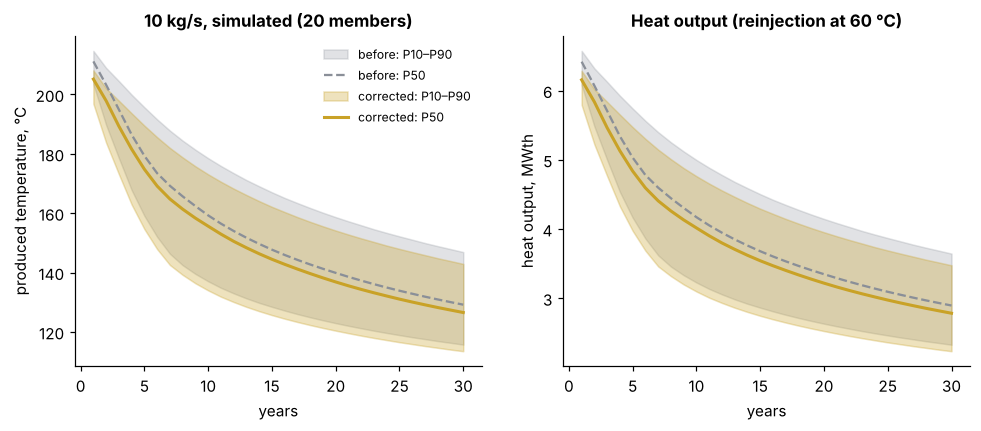

In [4]:
R = C["cases"]["gdr1222_recommended"]["rates"]
rows = []
for q in ("5", "10", "20"):
    for lab, key, f in (("start temperature, °C", "T_prod_initial_c", "{:.1f}"), ("temperature after 30 years, °C", "T_prod_end_c", "{:.1f}"),
                        ("heat in year 1, MWth", "power_initial_mw", "{:.2f}"), ("heat after 30 years, MWth", "power_end_mw", "{:.2f}"),
                        ("breakthrough (35 m cells), years", "breakthrough_years", "{:.2f}")):
        rows.append({"rate": f"{q} kg/s", "output": lab, "before (phase 4)": pct(B4[q][key], f), "after (corrected)": pct(R[q][key], f),
                     "change of P50": f"{R[q][key]['P50'] - B4[q][key]['P50']:+.2f}"})
display(pd.DataFrame(rows))
t = np.arange(1, 31)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
b4 = P4["ensemble"]["rates"]["barton_bandis"]["10"]
for a, key, ylab in ((ax[0], "T_prod_yearly_c", "produced temperature, °C"), (ax[1], "power_yearly_mw", "heat output, MWth")):
    a.fill_between(t, b4[key]["P10"], b4[key]["P90"], color=GREY, alpha=.25, label="before: P10–P90"); a.plot(t, b4[key]["P50"], color=GREY, ls="--", label="before: P50")
    a.fill_between(t, R["10"][key]["P10"], R["10"][key]["P90"], color=GOLD, alpha=.3, label="corrected: P10–P90"); a.plot(t, R["10"][key]["P50"], color=GOLD, lw=2, label="corrected: P50")
    a.set_xlabel("years"); a.set_ylabel(ylab)
ax[0].legend(fontsize=8); ax[0].set_title("10 kg/s, simulated (20 members)"); ax[1].set_title("Heat output (reinjection at 60 °C)")
fig.savefig("figures/forge_corrected_30_years.png"); plt.show()

**Reading.** The correction lowers the start by about 7 °C, but the 30-year temperature by less than half of that: after a few years the cold water from 16A, not the starting rock temperature, sets what 16B produces. Breakthrough barely moves. Heat output falls by a few percent, with the temperature difference to the 60 °C reinjection.

## 4 · The August 2024 check: most of the misfit was the temperature model

Notebook 4 left the model about 11 °C hotter than the bottom-hole temperature implied by the measured wellhead temperature. Notebook 6 tested local thermal non-equilibrium (LTNE) as the cause.

In [5]:
a = C["august"]
print(f"implied by the measured wellhead temperature (wellbore model, phase 4): {a['implied_T_bottomhole_c']:.1f} °C")
print(f"model at the 16B bottom hole: before {pct(B4['august']['T_bottomhole_c'])} °C → after {pct(a['T_bottomhole_c'])} °C")
print(f"misfit: before {pct(B4['august']['misfit_c'], '{:+.1f}')} °C → after {pct(a['misfit_c'], '{:+.1f}')} °C")
print(f"for comparison, LTNE without the correction (notebook 6, apertures refitted): {pct(P5['ltne_recalibrated']['summary']['misfit_ltne_c'], '{:+.1f}')} °C")
print(f"injector pressure in the test window: {pct(a['injector_bhp_mpa'], '{:.2f}')} MPa (measured {P4['wellbore']['injector_bhp_mpa']['P50']:.2f})")

implied by the measured wellhead temperature (wellbore model, phase 4): 202.9 °C
model at the 16B bottom hole: before 214.1 (212.6 to 215.5) °C → after 207.3 (205.5 to 208.8) °C
misfit: before +11.2 (+9.7 to +12.6) °C → after +4.4 (+2.7 to +5.9) °C
for comparison, LTNE without the correction (notebook 6, apertures refitted): +4.5 (-2.2 to +10.8) °C
injector pressure in the test window: 42.19 (41.83 to 42.56) MPa (measured 42.85)


**Reading.** With the corrected starting temperatures, the equilibrium model's misfit drops from about +11 °C to about +4 °C, close to what LTNE alone achieved in notebook 6. The two explanations overlap; the temperature model is measured, LTNE is not. We keep the equilibrium model for the forecasts and report LTNE as a sensitivity (notebook 6).

## 5 · The pressure limit under both Shmin cases

Each case sets both the limit and the normal stress on the stimulated fractures (Barton–Bandis). GDR 1222: the regional gradient. GDR 1596: the 16B minifracs as measured, carried down to 16A (the cautious case the case page leads with).

In [6]:
rows = []
for case, lab, before in (("gdr1222_recommended", "regional (GDR 1222)", B4["max_feasible_rate_kg_s"]),
                          ("gdr1596_unadjusted", "16B minifracs as measured (GDR 1596)", P5["shmin"]["summary"]["scenarios"]["gdr1596_unadjusted"]["max_feasible_rate_kg_s"])):
    c = C["cases"][case]
    rows.append({"Shmin case": lab, "Shmin at 16A top, MPa": round(c["shmin_top_16A_mpa"], 1), "highest rate before, kg/s": pct(before),
                 "highest rate after, kg/s": pct(c["max_feasible_rate_kg_s"]),
                 "members feasible": ", ".join(f"{q} kg/s: {c['rates'][q]['feasible_members']}/{C['ok']}" for q in c["rates"])})
display(pd.DataFrame(rows))
mf = E["minifrac_1570"]
print(f"GDR 1570 check: MF-2 shut-in pressures {', '.join(f'{v:.0f}' for v in mf['mf2_isip_psi'])} psi (report {', '.join(f'{v:.0f}' for v in mf['mf2_report_isip_psi'])}); "
      f"gradient {mf['mf2_gradient_psi_ft_kb']:.3f} psi/ft against the report's {mf['report_unadjusted_psi_ft']:.2f}")

,Shmin case,"Shmin at 16A top, MPa","highest rate before, kg/s","highest rate after, kg/s",members feasible
0,regional (GDR 1222),40.3,9.7 (9.3 to 10.5),9.8 (9.4 to 10.7),"5 kg/s: 20/20, 10 kg/s: 7/20, 20 kg/s: 0/20"
1,16B minifracs as measured (GDR 1596),32.2,0.0 (0.0 to 5.4),4.9 (3.6 to 6.1),"2.5 kg/s: 19/20, 5 kg/s: 9/20, 10 kg/s: 0/20"


GDR 1570 check: MF-2 shut-in pressures 3362, 3277, 3338 psi (report 3288, 3237, 3323); gradient 0.608 psi/ft against the report's 0.60


**Reading.** The correction hardly changes the pressure limit: colder water is a little more viscous, but each member's apertures are refitted to the measured August pressures, which absorbs most of it. The phase 5 'before' numbers for the minifrac case came from 8 members run at 5, 10 and 20 kg/s, so 'below 5 kg/s' was all they could say. With 2.5 kg/s added and 20 members, the highest rate is close to 5 kg/s, and about half of the members can take 5 kg/s for 30 years. The answer still turns on which Shmin is right: a minifrac in the reservoir section of 16A would settle it.

## 6 · The decision chart, re-tied

The proxy doublet of notebook 5 starts from 214 °C and is tied to the FORGE ensemble through the stimulated-slab thickness. Here its start moves by the change in the ensemble's initial produced temperature, the tie uses the corrected 30-year temperatures, and the surrogate is retrained (100 training and 25 held-out proxy runs). The criterion stays 'within 10 % of the way from the start to the reinjection temperature'. Sobol indices are not recomputed. *Surrogate values.*

In [7]:
D = E.get("decision")
if D:
    ch, ch4 = D["chart"], P4["decision"]["chart"]
    print(f"proxy start {214.0:.1f} → {D['proxy_T0_c']:.1f} °C; criterion {ch4['T_criterion_c']:.1f} → {ch['T_criterion_c']:.1f} °C")
    print(f"slab tie P50 {P4['decision']['tie_to_forge']['slab_m']['P50']:.0f} → {D['tie_to_forge']['slab_m']['P50']:.0f} m; surrogate held-out RMSE {D['surrogate_validation']['T_prod_end_c']['held_out']['gp']['rmse']:.1f} °C")
    display(pd.DataFrame([{"rate, kg/s": q, "spacing needed before (P50 / P10 case), m": f"{ch4['spacing_needed_m'][q]['P50'] or '> 800'} / {ch4['spacing_needed_m'][q]['P10'] or '> 800'}",
                           "after, m": f"{ch['spacing_needed_m'][q]['P50'] or '> 800'} / {ch['spacing_needed_m'][q]['P10'] or '> 800'}"} for q in ch["spacing_needed_m"]]))
else:
    print("decision re-tie not in this results file")

proxy start 214.0 → 207.1 °C; criterion 198.6 → 192.4 °C
slab tie P50 180 → 181 m; surrogate held-out RMSE 9.7 °C


,"rate, kg/s","spacing needed before (P50 / P10 case), m","after, m"
0,5,222.04145430462154 / 276.78088987423286,220.51494830258477 / 276.45758715474204
1,10,322.0605024492923 / 466.46185518000175,322.00188517214093 / 464.4918098137259
2,20,625.3172825587562 / 784.2386270249092,621.1056382395785 / 781.7745987166026
3,40,> 800 / > 800,> 800 / > 800
4,60,> 800 / > 800,> 800 / > 800
5,80,> 800 / > 800,> 800 / > 800


**Reading.** The criterion moves down with the start, and the 30-year temperatures move down by a similar amount, so the spacing a 30-year doublet needs hardly changes. The chart's main uncertainty is still the assumption that stimulation at a larger spacing makes a network like FORGE's today.

## 7 · Published numbers

The case page and the session report quote the numbers below. The notebook stops if a re-run of the engine moves any of them by more than 2 %.

In [8]:
G, K = E["geotherm"], E["geotherm"]["correction"]
R = C["cases"]["gdr1222_recommended"]["rates"]; M = C["cases"]["gdr1596_unadjusted"]
now = {"log16A_rmse": G["log_16A"]["rmse_c"], "log16A_bias": G["log_16A"]["bias_c"], "log16A_open_bias": G["log_16A"]["open_interval"]["bias_c"],
       "zone16B_bias": G["producing_zone_16B"]["model_minus_log_c"],
       "delta_mean_P50": K["delta_mid_c"]["mean_of_wells"]["P50"], "delta_mean_P10": K["delta_mid_c"]["mean_of_wells"]["P10"],
       "delta_mean_P90": K["delta_mid_c"]["mean_of_wells"]["P90"],
       "delta_16A_P50": K["delta_mid_c"]["16A(78)-32"]["P50"], "delta_16B_P50": K["delta_mid_c"]["16B(78)-32"]["P50"],
       "gauge_delta16B_P50": K["gauge_check"]["delta_16B_at_gauge_c"]["P50"], "gauge_misfit": K["gauge_check"]["gauge_model_minus_static_c"],
       "members": C["ok"],
       "august_misfit_before_P50": B4["august"]["misfit_c"]["P50"], "august_misfit_after_P50": C["august"]["misfit_c"]["P50"],
       "august_misfit_after_P10": C["august"]["misfit_c"]["P10"], "august_misfit_after_P90": C["august"]["misfit_c"]["P90"],
       "maxrate_1222_before_P50": B4["max_feasible_rate_kg_s"]["P50"], "maxrate_1222_after_P50": C["cases"]["gdr1222_recommended"]["max_feasible_rate_kg_s"]["P50"],
       "maxrate_1222_after_P10": C["cases"]["gdr1222_recommended"]["max_feasible_rate_kg_s"]["P10"],
       "maxrate_1222_after_P90": C["cases"]["gdr1222_recommended"]["max_feasible_rate_kg_s"]["P90"],
       "maxrate_1596_before_P50": P5["shmin"]["summary"]["scenarios"]["gdr1596_unadjusted"]["max_feasible_rate_kg_s"]["P50"],
       "maxrate_1596_after_P50": M["max_feasible_rate_kg_s"]["P50"], "maxrate_1596_after_P90": M["max_feasible_rate_kg_s"]["P90"],
       "mf2_gradient_psi_ft": E["minifrac_1570"]["mf2_gradient_psi_ft_kb"]}
for q in ("5", "10", "20"):
    for k, kk in (("T30", "T_prod_end_c"), ("T0", "T_prod_initial_c"), ("MW1", "power_initial_mw"), ("MW30", "power_end_mw"), ("bt", "breakthrough_years")):
        now[f"{k}_{q}_before_P50"] = B4[q][kk]["P50"]
        for p in ("P10", "P50", "P90"):
            now[f"{k}_{q}_after_{p}"] = R[q][kk][p]
D = E.get("decision")
if D:
    ch = D["chart"]
    now.update({"proxy_T0": D["proxy_T0_c"], "criterion_after": ch["T_criterion_c"], "criterion_before": P4["decision"]["chart"]["T_criterion_c"],
                "slab_after_P50": D["tie_to_forge"]["slab_m"]["P50"], "slab_before_P50": P4["decision"]["tie_to_forge"]["slab_m"]["P50"],
                "need10_after_P50": ch["spacing_needed_m"]["10"]["P50"], "need10_before_P50": P4["decision"]["chart"]["spacing_needed_m"]["10"]["P50"],
                "need20_after_P50": ch["spacing_needed_m"]["20"]["P50"], "need20_before_P50": P4["decision"]["chart"]["spacing_needed_m"]["20"]["P50"],
                "surrogate_rmse_after": D["surrogate_validation"]["T_prod_end_c"]["held_out"]["gp"]["rmse"]})

def band(d):
    return {k: d[k] for k in ("P10", "P50", "P90")}
web = {"run_id": E["run_id"],
       "correction": {"mean": band(K["delta_mid_c"]["mean_of_wells"]), "16A": band(K["delta_mid_c"]["16A(78)-32"]),
                      "16B": band(K["delta_mid_c"]["16B(78)-32"]), "tvd_range_m": K["tvd_range_m"],
                      "gauge": {"delta_16B": band(K["gauge_check"]["delta_16B_at_gauge_c"]), "misfit": K["gauge_check"]["gauge_model_minus_static_c"],
                                "range": K["gauge_check"]["gauge_range_c"]},
                      "log16A": {"rmse": G["log_16A"]["rmse_c"], "bias": G["log_16A"]["bias_c"], "open_bias": G["log_16A"]["open_interval"]["bias_c"],
                                 "zone16B_bias": G["producing_zone_16B"]["model_minus_log_c"], "bins": G["log_16A"]["bins"]}},
       "forecast": {q: {"T": R[q]["T_prod_yearly_c"], "MW": R[q]["power_yearly_mw"], "T30": band(R[q]["T_prod_end_c"]), "T0": band(R[q]["T_prod_initial_c"]),
                        "MW1": band(R[q]["power_initial_mw"]), "MW30": band(R[q]["power_end_mw"]), "bt": band(R[q]["breakthrough_years"]),
                        "bhp": band(R[q]["injector_bhp_max_mpa"]), "feasible_members": R[q]["feasible_members"],
                        "before": {"T30": band(B4[q]["T_prod_end_c"]), "T0": band(B4[q]["T_prod_initial_c"]), "MW1": band(B4[q]["power_initial_mw"]),
                                   "MW30": band(B4[q]["power_end_mw"]), "bt": band(B4[q]["breakthrough_years"])}} for q in ("5", "10", "20")},
       "august": {"misfit": band(C["august"]["misfit_c"]), "T_bh": band(C["august"]["T_bottomhole_c"]), "before_misfit": band(B4["august"]["misfit_c"]),
                  "implied": C["august"]["implied_T_bottomhole_c"]},
       "shmin": {case: {"shmin_top_16A_mpa": c["shmin_top_16A_mpa"], "gradient_mpa_per_km": c["gradient_mpa_per_km"], "max_rate": band(c["max_feasible_rate_kg_s"]),
                        "feasible_members": {q: c["rates"][q]["feasible_members"] for q in c["rates"]},
                        "bhp": {q: band(c["rates"][q]["injector_bhp_max_mpa"]) for q in c["rates"]}} for case, c in C["cases"].items()},
       "shmin_before": {"gdr1222_recommended": band(B4["max_feasible_rate_kg_s"]),
                        "gdr1596_unadjusted": band(P5["shmin"]["summary"]["scenarios"]["gdr1596_unadjusted"]["max_feasible_rate_kg_s"])},
       "members": C["ok"]}
if D:
    ch = D["chart"]
    cells = {(c["rate_kg_s"], c["spacing_m"]): c for c in ch["cells"]}
    web["decision"] = {"spacings_m": ch["spacings_m"], "rates_kg_s": ch["rates_kg_s"], "criterion_c": ch["T_criterion_c"], "need": ch["spacing_needed_m"],
                       "T30_P50": [[cells[(q, L)].get("T30_c", {}).get("P50") for L in ch["spacings_m"]] for q in ch["rates_kg_s"]],
                       "T30_P10": [[cells[(q, L)].get("T30_c", {}).get("P10") for L in ch["spacings_m"]] for q in ch["rates_kg_s"]],
                       "T30_P90": [[cells[(q, L)].get("T30_c", {}).get("P90") for L in ch["spacings_m"]] for q in ch["rates_kg_s"]],
                       "rmse_T30": D["surrogate_validation"]["T_prod_end_c"]["held_out"]["gp"]["rmse"], "proxy_T0_c": D["proxy_T0_c"],
                       "slab": D["tie_to_forge"]["slab_m"], "label": ch["label"]}
print(json.dumps(now, indent=1))

{
 "log16A_rmse": 7.111220120825339,
 "log16A_bias": 6.984532078417527,
 "log16A_open_bias": 5.906783794364893,
 "zone16B_bias": 8.241582973407496,
 "delta_mean_P50": 5.9041251119955085,
 "delta_mean_P10": 5.096860000694674,
 "delta_mean_P90": 6.734380852639278,
 "delta_16A_P50": 4.962193376743569,
 "delta_16B_P50": 6.851245597207688,
 "gauge_delta16B_P50": 7.9652937028957975,
 "gauge_misfit": 5.735969066204575,
 "members": 20,
 "august_misfit_before_P50": 11.172836391230462,
 "august_misfit_after_P50": 4.387494680729972,
 "august_misfit_after_P10": 2.6644667924485987,
 "august_misfit_after_P90": 5.874478605064278,
 "maxrate_1222_before_P50": 9.697774906884248,
 "maxrate_1222_after_P50": 9.826538095759584,
 "maxrate_1222_after_P10": 9.38177513118848,
 "maxrate_1222_after_P90": 10.72028468263056,
 "maxrate_1596_before_P50": 0.0,
 "maxrate_1596_after_P50": 4.865554065966016,
 "maxrate_1596_after_P90": 6.122043122420513,
 "mf2_gradient_psi_ft": 0.6075851144702643,
 "T30_5_before_P50": 153

In [9]:
published = {'log16A_rmse': 7.111220120825339, 'log16A_bias': 6.984532078417527, 'log16A_open_bias': 5.906783794364893, 'zone16B_bias': 8.241582973407496, 'delta_mean_P50': 5.9041251119955085, 'delta_mean_P10': 5.096860000694674, 'delta_mean_P90': 6.734380852639278, 'delta_16A_P50': 4.962193376743569, 'delta_16B_P50': 6.851245597207688, 'gauge_delta16B_P50': 7.9652937028957975, 'gauge_misfit': 5.735969066204575, 'members': 20, 'august_misfit_before_P50': 11.172836391230462, 'august_misfit_after_P50': 4.387494680729972, 'august_misfit_after_P10': 2.6644667924485987, 'august_misfit_after_P90': 5.874478605064278, 'maxrate_1222_before_P50': 9.697774906884248, 'maxrate_1222_after_P50': 9.826538095759584, 'maxrate_1222_after_P10': 9.38177513118848, 'maxrate_1222_after_P90': 10.72028468263056, 'maxrate_1596_before_P50': 0.0, 'maxrate_1596_after_P50': 4.865554065966016, 'maxrate_1596_after_P90': 6.122043122420513, 'mf2_gradient_psi_ft': 0.6075851144702643, 'T30_5_before_P50': 153.18047777435635, 'T30_5_after_P10': 133.40795407854807, 'T30_5_after_P50': 149.80580743542095, 'T30_5_after_P90': 164.5156305972387, 'T0_5_before_P50': 213.72280154123268, 'T0_5_after_P10': 204.86431887545206, 'T0_5_after_P50': 206.78030151190075, 'T0_5_after_P90': 208.72732092877985, 'MW1_5_before_P50': 3.2664734417125363, 'MW1_5_after_P10': 3.0606935655266994, 'MW1_5_after_P50': 3.1158005722475863, 'MW1_5_after_P90': 3.1603948939234328, 'MW30_5_before_P50': 1.955793554324974, 'MW30_5_after_P10': 1.536605217109872, 'MW30_5_after_P50': 1.8840144744032479, 'MW30_5_after_P90': 2.197676745256512, 'bt_5_before_P50': 3.5039919372856954, 'bt_5_after_P10': 1.9580460431874256, 'bt_5_after_P50': 3.634981887480741, 'bt_5_after_P90': 5.701887915042491, 'T30_10_before_P50': 129.1651782060984, 'T30_10_after_P10': 113.48624743989394, 'T30_10_after_P50': 126.52090790301003, 'T30_10_after_P90': 142.90352658590464, 'T0_10_before_P50': 213.72450153685267, 'T0_10_after_P10': 204.8924764384026, 'T0_10_after_P50': 206.78268413390083, 'T0_10_after_P90': 208.72190128929043, 'MW1_10_before_P50': 6.416449882696867, 'MW1_10_after_P10': 5.792458200655164, 'MW1_10_after_P50': 6.154150655648148, 'MW1_10_after_P90': 6.28321756921437, 'MW30_10_before_P50': 2.8941051188649283, 'MW30_10_after_P10': 2.2342733285832153, 'MW30_10_after_P50': 2.7826002551848417, 'MW30_10_after_P90': 3.4750510355365183, 'bt_10_before_P50': 1.707371356560627, 'bt_10_after_P10': 0.939920583682823, 'bt_10_after_P50': 1.773987783014417, 'bt_10_after_P90': 2.783089711724847, 'T30_20_before_P50': 106.42910528394411, 'T30_20_after_P10': 97.73662726071802, 'T30_20_after_P50': 104.69004576934702, 'T30_20_after_P90': 120.31347484879372, 'T0_20_before_P50': 213.7282805064377, 'T0_20_after_P10': 204.96846344673196, 'T0_20_after_P50': 206.78780937308332, 'T0_20_after_P90': 208.70519448925384, 'MW1_20_before_P50': 12.180411345970972, 'MW1_20_after_P10': 10.451909831132227, 'MW1_20_after_P50': 11.697685972233916, 'MW1_20_after_P90': 11.99886529539433, 'MW30_20_before_P50': 3.8763813046805176, 'MW30_20_after_P10': 3.14837629625222, 'MW30_20_after_P50': 3.730616392690724, 'MW30_20_after_P90': 5.042452775115838, 'bt_20_before_P50': 0.8594146293206056, 'bt_20_after_P10': 0.45135143102469294, 'bt_20_after_P50': 0.8881928177935209, 'bt_20_after_P90': 1.341538598526474, 'proxy_T0': 207.05818259704816, 'criterion_after': 192.35236433734335, 'criterion_before': 198.6, 'slab_after_P50': 180.77390491951135, 'slab_before_P50': 180.27362267954922, 'need10_after_P50': 322.00188517214093, 'need10_before_P50': 322.0605024492923, 'need20_after_P50': 621.1056382395785, 'need20_before_P50': 625.3172825587562, 'surrogate_rmse_after': 9.706775841459669}
for k, v in published.items():
    x = now[k]
    if isinstance(v, (str, bool)) or v is None or x is None:
        assert x == v, (k, x, v)
    else:
        assert abs(x - v) <= 0.02 * abs(v) + 0.01, (k, x, v)
pathlib.Path("results/nb7_geotherm_correction.json").write_text(json.dumps({"published": now, "web": web, "run_id": E["run_id"]}, indent=1))
print(f"all {len(published)} published numbers reproduced")

all 94 published numbers reproduced


**Limits.** The correction rests on one log in one well, assumed to hold across the 100–300 m to 16B at the same depth; the 16B gauge agrees within its own wide range. It is constant in plan view apart from the weighting between the wells, and fitted as a straight line in depth over the reservoir depths only. The wellbore model's implied bottom-hole temperature is kept from phase 4 (it already samples a ±10 °C geotherm offset). All forecasts are simulated.